## Importing libraries

In [ ]:
!pip install missingno

In [ ]:
# import required libraries for dataframe and visualization

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
import missingno as mno

# import required libraries for clustering
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage
from scipy.cluster.hierarchy import dendrogram
from scipy.cluster.hierarchy import cut_tree

import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

## Explore our dataset

In [ ]:
!pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.9/250.9 kB 4.2 MB/s eta 0:00:00


The columns are descrived as follows :

In [ ]:
df = pd.read_excel('/content/OnlineRetail.xlsx')
df.head(20)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


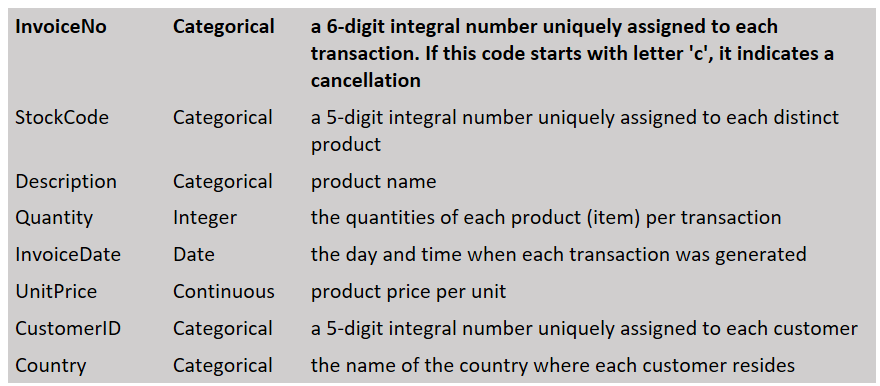

In [ ]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303


<Axes: >

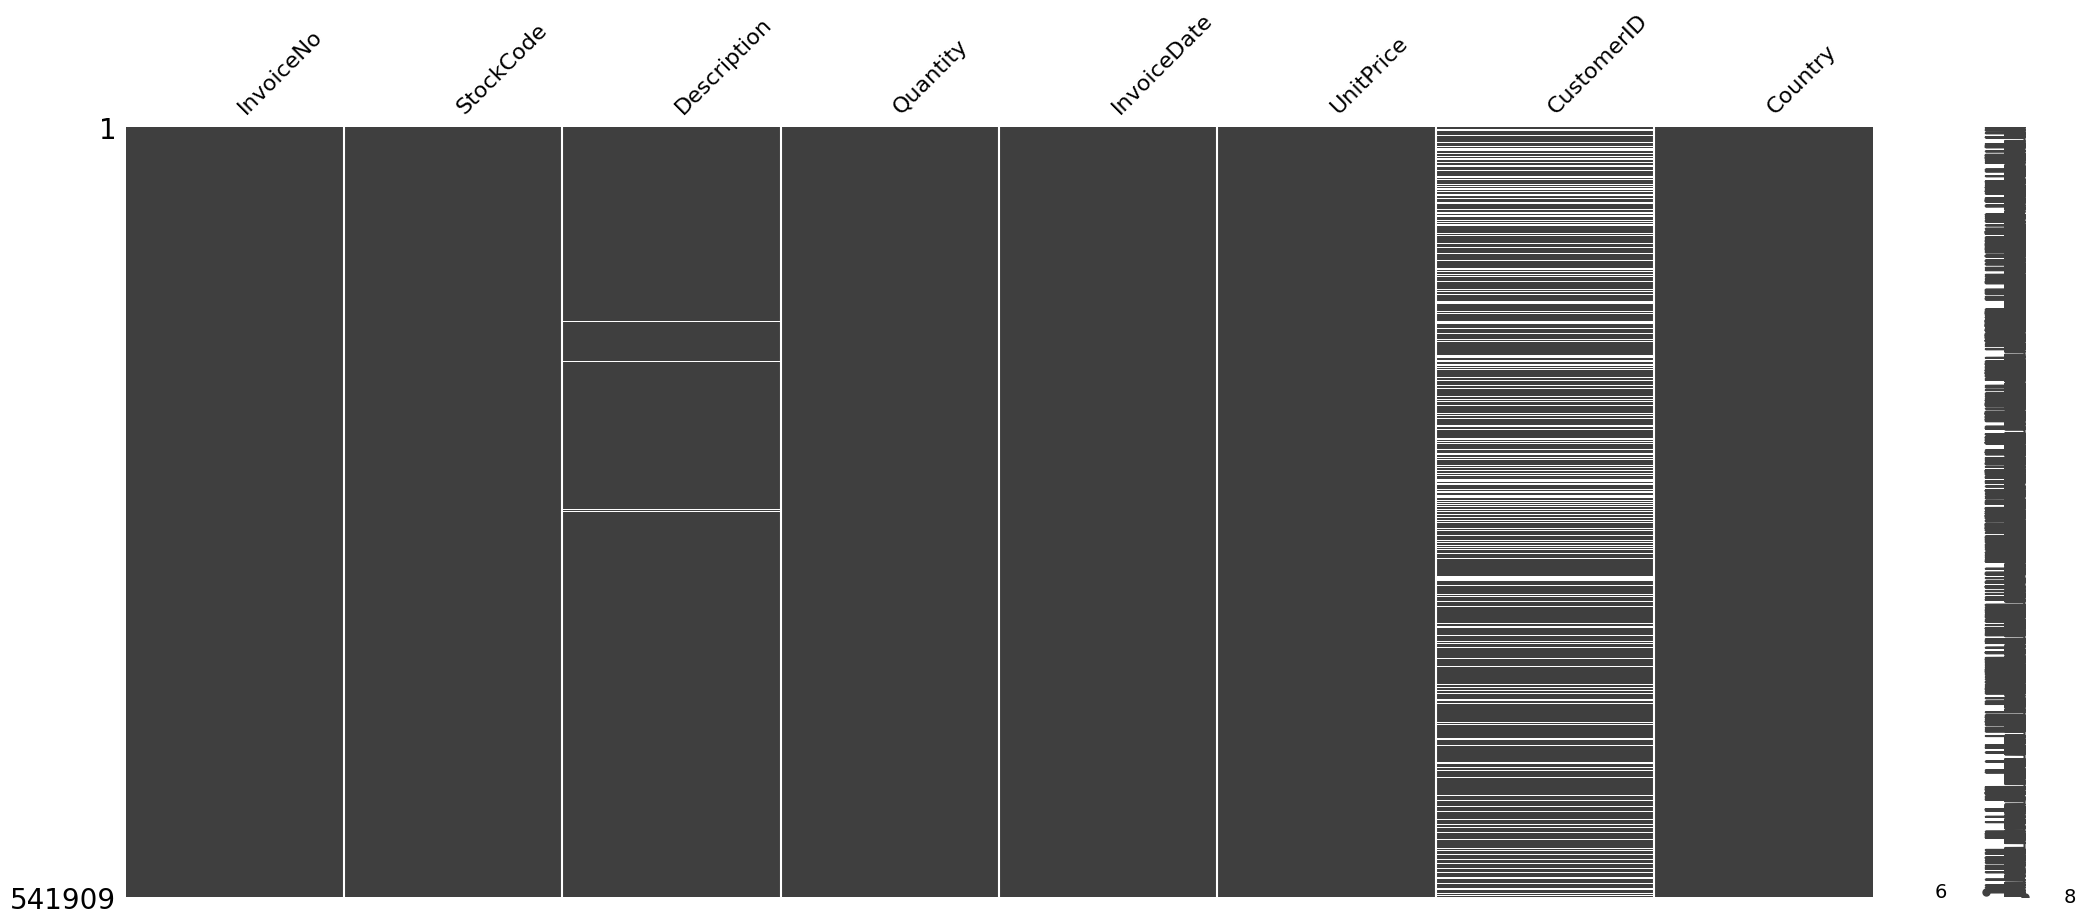

In [ ]:
mno.matrix(df)

We have a lot of missing values

In [ ]:
df['Country'].value_counts()

,count
Country,
United Kingdom,495478
Germany,9495
France,8557
EIRE,8196
Spain,2533
Netherlands,2371
Belgium,2069
Switzerland,2002
Portugal,1519


In [ ]:
df['Country'].value_counts(normalize=True)

,proportion
Country,
United Kingdom,0.914320
Germany,0.017521
France,0.015790
EIRE,0.015124
Spain,0.004674
Netherlands,0.004375
Belgium,0.003818
Switzerland,0.003694
Portugal,0.002803


In [ ]:
import plotly.express as px


top_10_countries_percent = df['Country'].value_counts(normalize=True)[:10]
fig = px.bar(y=top_10_countries_percent.values,
             x=top_10_countries_percent.index,
             color = top_10_countries_percent.index,
             color_discrete_sequence=px.colors.sequential.PuBuGn,
             text=top_10_countries_percent.values,
             title= 'Top 10 Countries by %')
fig.update_layout(
    xaxis_title="Countries",
    yaxis_title="count",
    font = dict(size=17,family="Franklin Gothic"))
fig.show()

In [ ]:
top_10_countries_percent = df['Country'].value_counts()[:10]
fig = px.bar(y=top_10_countries_percent.values,
             x=top_10_countries_percent.index,
             color = top_10_countries_percent.index,
             color_discrete_sequence=px.colors.sequential.PuBuGn,
             text=top_10_countries_percent.values,
             title= 'Top 10 Countries per count')
fig.update_layout(
    xaxis_title="Countries",
    yaxis_title="count",
    font = dict(size=17,family="Franklin Gothic"))
fig.show()

In [ ]:
# Top 10 products by quantity
top_10_products = df.groupby('Description')['Quantity'].sum().sort_values(ascending=False)[:10]

fig = px.bar(y=top_10_products.index,
             x=top_10_products.values,
             color=top_10_products.index,
             color_discrete_sequence=px.colors.sequential.PuBuGn,
             text=top_10_products.values,
             title='Top 10 Products by Quantity')

fig.update_layout(
    xaxis_title="Quantity",
    yaxis_title="Product Description",
    font=dict(size=17, family="Franklin Gothic"))

fig.update_traces(texttemplate='%{text:.0f}', textposition='outside')

fig.show()

WORLD WAR 2 GLIDERS ASSTD DESIGNS is the highest selling product

In [ ]:
# Top 10 least selling products
bottom_10_products = df.groupby('Description')['Quantity'].sum().sort_values(ascending=True)[:10]

fig = px.bar(y=bottom_10_products.index,
             x=bottom_10_products.values,
             color=bottom_10_products.index,
             color_discrete_sequence=px.colors.sequential.PuBuGn,
             text=bottom_10_products.values,
             title='Top 10 Least Selling Products')

fig.update_layout(
    xaxis_title="Quantity",
    yaxis_title="Product Description",
    font=dict(size=17, family="Franklin Gothic"))

fig.update_traces(texttemplate='%{text:.0f}', textposition='outside')

fig.show()

There seem to be some returns, damaged and not up-to-selling standard products in there

In [ ]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [ ]:
# Who are the top spending clients?

Top10Spending=df.groupby('CustomerID')['Quantity'].sum().reset_index().sort_values('Quantity',ascending=False).head(10)
Top10Spending

,CustomerID,Quantity
1703,14646.0,196719
55,12415.0,77242
1895,14911.0,77180
3758,17450.0,69029
4233,18102.0,64122
3801,17511.0,63012
1005,13694.0,61803
1447,14298.0,58021
1345,14156.0,57025
3202,16684.0,49390


Not very helpfull, let's do a simple Viz

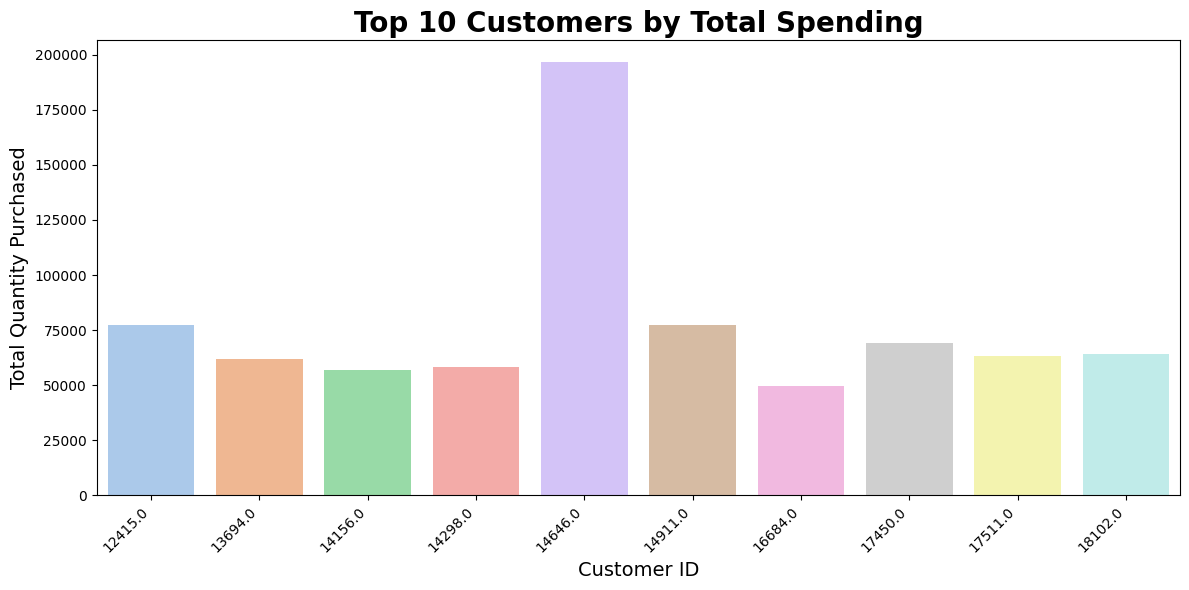

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Top 10 customers by spending
Top10Spending = df.groupby('CustomerID')['Quantity'].sum().sort_values(ascending=False).head(10).reset_index()

# Create the plot
plt.figure(figsize=(12, 6))
sns.barplot(x='CustomerID', y='Quantity', data=Top10Spending, palette='pastel')

# Customize the plot
plt.title('Top 10 Customers by Total Spending', fontsize=20, fontweight='bold')
plt.xlabel('Customer ID', fontsize=14)
plt.ylabel('Total Quantity Purchased', fontsize=14)
plt.xticks(rotation=45, ha='right')

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

## Let's start cleaning and data pre-processing

In [ ]:
# Let's do a copy of the dataset and explore it a bit without touching the original!

retail = df.copy()
retail

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [ ]:
print('The size of Dataframe is: ', retail.shape)
print('-'*100)
print('The Column Name, Record Count and Data Types are as follows: ')
retail.info()
print('-'*100)

The size of Dataframe is:  (541909, 8)
----------------------------------------------------------------------------------------------------
The Column Name, Record Count and Data Types are as follows: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
----------------------------------------------------------------------------------------------------


In [ ]:
# Separate columns into numerical and categorical
numeric_features = retail.select_dtypes(exclude=['object']).columns
categorical_features = retail.select_dtypes(include=['object']).columns

# Print the results
print(f"We have {len(numeric_features)} numerical features: {list(numeric_features)}")
print(f"\nWe have {len(categorical_features)} categorical features: {list(categorical_features)}")

We have 4 numerical features: ['Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID']

We have 4 categorical features: ['InvoiceNo', 'StockCode', 'Description', 'Country']


In [ ]:
print("Missing values in each column:")
print("-" * 50)

missing_data = retail.isnull().sum().sort_values(ascending=False)
missing_percent = (missing_data / len(retail) * 100).round(2)

result = pd.DataFrame({
    'Total': missing_data,
    'Percent': missing_percent
})

print(result)

Missing values in each column:
--------------------------------------------------
              Total  Percent
CustomerID   135080    24.93
Description    1454     0.27
StockCode         0     0.00
InvoiceNo         0     0.00
Quantity          0     0.00
InvoiceDate       0     0.00
UnitPrice         0     0.00
Country           0     0.00


In [ ]:
retail.CustomerID.unique().shape

(4373,)

Since 24.93% of Customer ID entries are missing, we need to carefully consider how to handle this column rather than immediately dropping it.

Dropping 24.93% of the data could significantly skew our analysis and lead to biased results.

ftercarefull investigation, we considered that imputing values wasn't the best solution since the data that is missing is systematic and may indicate a data collection or management issue that should be addressed for future data quality, but right now we prefer not inducing further bias and delete it.

In [ ]:
# Dropping empmty values

retail = retail.dropna()
retail.shape

(406829, 8)

In [ ]:
# Let's have a look
retail.describe().T

,count,mean,min,25%,50%,75%,max,std
Quantity,406829.0,12.061303,-80995.0,2.0,5.0,12.0,80995.0,248.69337
InvoiceDate,406829,2011-07-10 16:30:57.879207424,2010-12-01 08:26:00,2011-04-06 15:02:00,2011-07-31 11:48:00,2011-10-20 13:06:00,2011-12-09 12:50:00,NaN
UnitPrice,406829.0,3.460471,0.0,1.25,1.95,3.75,38970.0,69.315162
CustomerID,406829.0,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303


In [ ]:
# Sanity check
retail.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0


Changing DataType

In [ ]:
retail['CustomerID'] = retail['CustomerID'].astype(str)

In [ ]:
retail.dtypes

,0
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,object
Country,object


In [ ]:
# We have seen some negatives values that we will not be treating since we do not have information on it
# Let's observe and drop them
(retail['UnitPrice']<=0).value_counts()

,count
UnitPrice,
False,406789
True,40


In [ ]:
retail = retail[retail['UnitPrice']>0]
# Let's see it
(retail['Quantity']<=0).value_counts()

,count
Quantity,
False,397884
True,8905


In [ ]:
retail = retail[retail['Quantity']>=0]
retail

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


## RFM SEGMENTATION

What Is RFM Analysis?
RFM stands for Recency, Frequency, and Monetary value. It is a method to analyze customer behavior and segment them into groups for better business decisions.

- Recency (R): How recently a customer made a purchase.
- Frequency (F): How often a customer makes purchases.
- Monetary Value (M): How much money a customer spends.

Why RFM Analysis?
1)Identify loyal customers.
2)Spot high-value customers.
3)Target lapsed customers with campaigns.


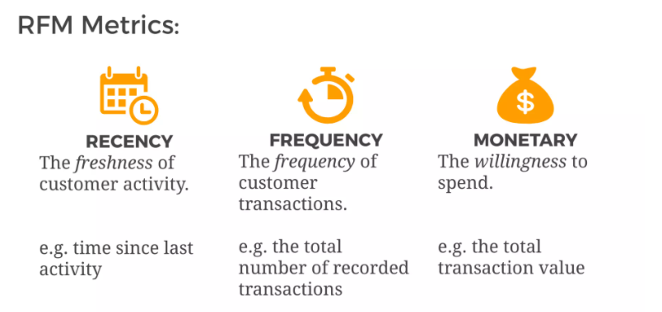

Source image : (https://www.slideshare.net/slideshow/rfm-segmentation/46901188#6)

Since we don't have thos values let's create them!

## Monetary Value

In [ ]:
# First let's do the Monetary value and round it!

retail['Monetary'] = round(retail['Quantity'] * retail['UnitPrice'], 2)

In [ ]:
retail

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Monetary
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60


In [ ]:
# Calculate total monetary value for each customer
rfm_m = retail.groupby('CustomerID')['Monetary'].sum().reset_index()

# Rename the sum column to 'Monetary' (optional, as it's already named correctly)
# rfm_m.columns = ['CustomerID', 'Monetary']

# Display the first few rows
print(rfm_m.head())

  CustomerID  Monetary
0    12346.0  77183.60
1    12347.0   4310.00
2    12348.0   1797.24
3    12349.0   1757.55
4    12350.0    334.40


So this is the monetary value of each customer for all of their transactions

## Frequency

In [ ]:
# Let's do Frequency now :

# Calculate frequency (number of purchases) for each customer
rfm_f = retail.groupby('CustomerID')['InvoiceNo'].nunique().reset_index()

# Rename the count column to 'Frequency'
rfm_f.columns = ['CustomerID', 'Frequency']

# Display the first few rows
print(rfm_f.head())

  CustomerID  Frequency
0    12346.0          1
1    12347.0          7
2    12348.0          4
3    12349.0          1
4    12350.0          1


In [ ]:
# Merge Monetary and Frequency dataframes on CustomerID
rfm = pd.merge(rfm_m, rfm_f, on='CustomerID')

# Display the first few rows of the merged dataframe
print(rfm.head())

  CustomerID  Monetary  Frequency
0    12346.0  77183.60          1
1    12347.0   4310.00          7
2    12348.0   1797.24          4
3    12349.0   1757.55          1
4    12350.0    334.40          1


Everything seems good, let's keep going!

## Recency

In [ ]:
# Get the minimum and maximum dates from the 'InvoiceDate' column
min_date = retail['InvoiceDate'].min()
max_date = retail['InvoiceDate'].max()

# Display the date range
print(f"Date range: {min_date} to {max_date}")

Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


In [ ]:
# Compute the difference between max date and each transaction date
retail['Diff_Days'] = (max_date - retail['InvoiceDate']).dt.days

# Display the first few rows of the updated dataframe
print(retail[['InvoiceDate', 'Diff_Days']].head())

          InvoiceDate  Diff_Days
0 2010-12-01 08:26:00        373
1 2010-12-01 08:26:00        373
2 2010-12-01 08:26:00        373
3 2010-12-01 08:26:00        373
4 2010-12-01 08:26:00        373


In [ ]:
# Compute recency (days since last purchase) for each customer
rfm_r = retail.groupby('CustomerID')['Diff_Days'].min().reset_index()

# Rename the column for clarity
rfm_r.columns = ['CustomerID', 'Recency']

# Display the first few rows
print(rfm_r.head())

  CustomerID  Recency
0    12346.0      325
1    12347.0        1
2    12348.0       74
3    12349.0       18
4    12350.0      309


In [ ]:
# Ensure Recency is in integer days format
rfm_r['Recency'] = rfm_r['Recency'].astype(int)

# Display the first few rows
print(rfm_r.head())

  CustomerID  Recency
0    12346.0      325
1    12347.0        1
2    12348.0       74
3    12349.0       18
4    12350.0      309


In [ ]:
# Merge all RFM attributes (Monetary, Frequency, Recency) on CustomerID
rfm = pd.merge(rfm, rfm_r, on='CustomerID')

# Ensure column order and naming
rfm = rfm[['CustomerID', 'Monetary', 'Frequency', 'Recency']]

# Display the first few rows of the final RFM dataframe
print(rfm.head())

  CustomerID  Monetary  Frequency  Recency
0    12346.0  77183.60          1      325
1    12347.0   4310.00          7        1
2    12348.0   1797.24          4       74
3    12349.0   1757.55          1       18
4    12350.0    334.40          1      309


Ok now we have our RFM foreach customer, let's see somme stats!


In [ ]:
rfm.describe().T

,count,mean,std,min,25%,50%,75%,max
Monetary,4338.0,2054.266459,8989.230441,3.75,307.415,674.485,1661.74,280206.02
Frequency,4338.0,4.272015,7.697998,1.00,1.000,2.000,5.00,209.00
Recency,4338.0,91.536422,100.014169,0.00,17.000,50.000,141.00,373.00


In [ ]:
rfm_description = rfm.describe().T.reset_index()

# Rename columns for better readability
rfm_description.columns = ['Metric', 'Count', 'Mean', 'Std', 'Min', '25%', '50%', '75%', 'Max']

# Create a bar chart for the descriptive statistics
fig = px.bar(rfm_description,
             x='Metric',
             y='Mean',
             title='Descriptive Statistics of RFM Metrics',
             text='Mean',
             color='Metric',
             color_discrete_sequence=px.colors.sequential.Plasma)

# Update layout for better readability
fig.update_layout(
    xaxis_title="Metrics",
    yaxis_title="Mean Value",
    font=dict(size=14),
    xaxis_tickangle=-45
)

# Show the figure
fig.show()

In [ ]:
rfm.shape

(4338, 4)

Plot the customers in a 3D plot where each axis is the log value of the previous metrics.

In [ ]:
" Let's do a copy again since we will do some transformations"

rfm_data = rfm.copy()

Now the plot

In [ ]:
# Log-transform the metrics
rfm_data['Log_Recency'] = np.log1p(rfm_data['Recency'])      # log(Recency + 1)
rfm_data['Log_Frequency'] = np.log1p(rfm_data['Frequency'])  # log(Frequency + 1)
rfm_data['Log_Monetary'] = np.log1p(rfm_data['Monetary'])    # log(Monetary + 1)

# Create a 3D scatter plot
fig = px.scatter_3d(
    rfm_data,
    x='Log_Recency',
    y='Log_Frequency',
    z='Log_Monetary',
    color='CustomerID',   # Color by CustomerID for differentiation
    title='3D Plot of Customers by Log-Transformed RFM Metrics',
    labels={'Log_Recency': 'Log Recency',
            'Log_Frequency': 'Log Frequency',
            'Log_Monetary': 'Log Monetary'}
)

# Show the plot
fig.show()